# Decision Tree Classifier — CUB-200-2011 Tabular Attributes

This notebook classifies 200 bird species from the 312 image-level attribute labels, using a single decision tree.

**Input:** the feature files written by [`dataPrep.ipynb`](dataPrep.ipynb) (run that first).
**Protocol:** official train/test split (`SPLIT = 'is_train'`; the 80/20 version is [`decisionTree_80_20.ipynb`](decisionTree_80_20.ipynb)). All tuning and variant selection use stratified 5-fold CV on the **training set only**. The test set is used once, at the end.

| Step | Section |
|---|---|
| Baseline (default tree) | 2 |
| Validation curves for each hyperparameter | 3 |
| Grid search | 4 |
| Feature variant comparison (A / B / C) | 5 |
| Final test evaluation | 6 |
| Error analysis | 7 |
| Interpretation (tree, rules, feature importances) | 8 |

## 1. Setup

Evaluation choices, shared with the Random Forest notebook so the two models are directly comparable:
- **Stratified 5-fold CV on the training set** is used for all tuning. Stratification keeps the 29–30 images per species balanced across folds, giving about 6 per species in each validation fold. 5 folds balances the variance of the estimate against runtime. With only about 30 images per class, a separate fixed validation split would be too small to be reliable.
- **Accuracy is the selection metric.** The training classes are balanced, so accuracy and macro-F1 rank models almost identically. Macro-F1 is still reported, because the *test* classes range from 11 to 30 images.
- **Top-5 accuracy** is reported at the end as a secondary metric, to show whether the correct species is at least among the model's top guesses.
- **`RANDOM_STATE = 42`** fixes the folds and the tree's tie-breaking, so every number in this notebook is reproducible.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, validation_curve
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix

RANDOM_STATE = 42
SPLIT = 'is_train'  # official split; decisionTree_80_20.ipynb uses 'is_train_80'
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']  # never used as features

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

def load_variant(name):
    """Return X_train, y_train, X_test, y_test for feature variant A, B or C."""
    path = DATA / f'cub_features_{name}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path)
    features = [c for c in df.columns if c not in META_COLS]
    train, test = df[df[SPLIT] == 1], df[df[SPLIT] == 0]
    return train[features], train.class_id, test[features], test.class_id

X_train, y_train, X_test, y_test = load_variant('A')
class_names = pd.read_csv(DATA / 'cub_features_A.csv', usecols=['class_id', 'class_name']) \
                .drop_duplicates().set_index('class_id').class_name.sort_index()

print('train', X_train.shape, '| test', X_test.shape, '| classes', y_train.nunique())
print(f'chance accuracy: {1 / y_train.nunique():.3%}')

train (5994, 312) | test (5794, 312) | classes 200
chance accuracy: 0.500%


## 2. Baseline: default decision tree

The default tree is the reference point. Any tuning has to beat it on CV to be worth keeping. An unrestricted tree grows until every leaf is pure, so it should memorise the training set. The gap between training accuracy and CV accuracy measures how much it overfits.

In [2]:
baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
cv_base = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)

baseline.fit(X_train, y_train)
print(f'depth: {baseline.get_depth()}, leaves: {baseline.get_n_leaves()}')
print(f"train accuracy (CV folds): {cv_base['train_accuracy'].mean():.3f}")
print(f"CV accuracy:               {cv_base['test_accuracy'].mean():.3f} ± {cv_base['test_accuracy'].std():.3f}")
print(f"CV macro-F1:               {cv_base['test_f1_macro'].mean():.3f} ± {cv_base['test_f1_macro'].std():.3f}")

depth: 46, leaves: 3429
train accuracy (CV folds): 0.999
CV accuracy:               0.247 ± 0.005
CV macro-F1:               0.241 ± 0.005


## 3. Validation curves

**Why:** searching a grid blind wastes runtime and can miss the useful range. We first vary one hyperparameter at a time (the others at their defaults), for both split criteria. This shows where performance changes, so the grid in §4 can focus there.

- `max_depth`, `min_samples_leaf` and `min_samples_split` are the standard pre-pruning controls (they stop the tree growing early). `ccp_alpha` is post-pruning (grow fully, then cut back weak branches). Testing both families shows whether *any* kind of regularisation helps.
- The `ccp_alpha` values are taken from quantiles of the baseline tree's own **pruning path**, rather than an arbitrary grid. This guarantees that each value actually removes a different number of branches.
- Each panel shows both train (dashed) and CV (solid) accuracy. The gap between them is the overfitting.

**Reading the curves:**
- CV accuracy rises with `max_depth` up to about 20 and then plateaus. Shallower trees underfit.
- Larger `min_samples_leaf`/`min_samples_split` and larger `ccp_alpha` reduce training accuracy a lot, but do **not** raise CV accuracy. CV accuracy stays flat or falls.
- Gini is consistently a few points above entropy.

So regularisation does not look helpful here, but the grid still tests combinations, in case they interact.

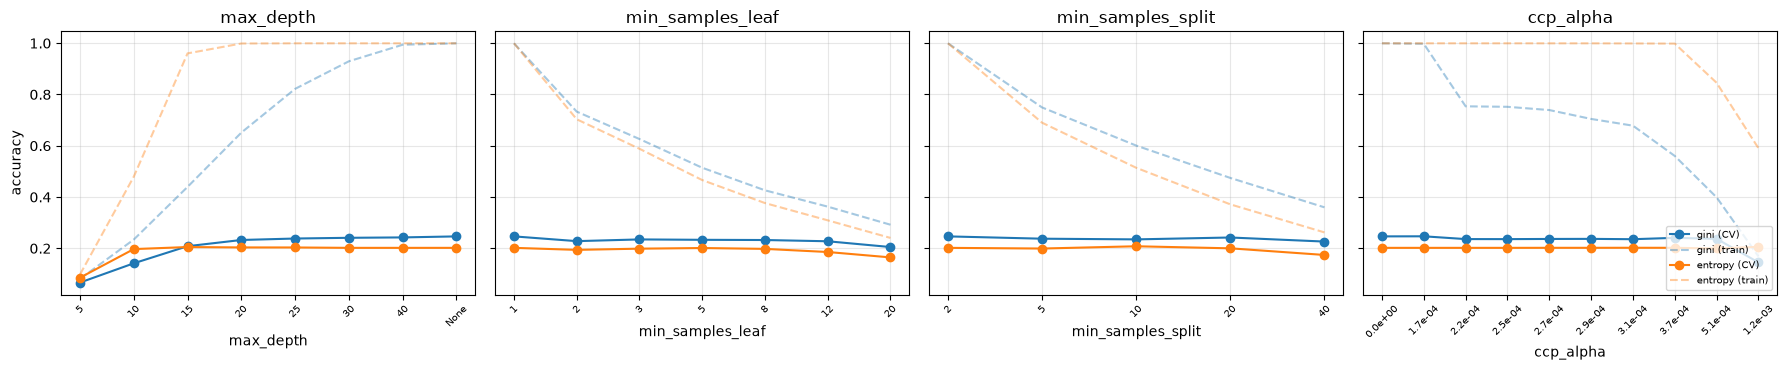

In [3]:
ccp_path = baseline.cost_complexity_pruning_path(X_train, y_train)
alpha_grid = np.unique(np.quantile(ccp_path.ccp_alphas, np.linspace(0, 0.98, 12)).round(6))

curves = {
    'max_depth': [5, 10, 15, 20, 25, 30, 40, None],
    'min_samples_leaf': [1, 2, 3, 5, 8, 12, 20],
    'min_samples_split': [2, 5, 10, 20, 40],
    'ccp_alpha': list(alpha_grid),
}

fig, axes = plt.subplots(1, len(curves), figsize=(18, 3.8), sharey=True)
for ax, (param, values) in zip(axes, curves.items()):
    for criterion, colour in [('gini', 'tab:blue'), ('entropy', 'tab:orange')]:
        tr, va = validation_curve(DecisionTreeClassifier(criterion=criterion, random_state=RANDOM_STATE),
                                  X_train, y_train, param_name=param, param_range=values,
                                  cv=CV, scoring='accuracy', n_jobs=-1)
        x = np.arange(len(values))
        ax.plot(x, va.mean(1), 'o-', color=colour, label=f'{criterion} (CV)')
        ax.plot(x, tr.mean(1), '--', color=colour, alpha=0.4, label=f'{criterion} (train)')
    ax.set_xticks(x, [str(v) if not isinstance(v, float) else f'{v:.1e}' for v in values],
                  rotation=45, fontsize=7)
    ax.set(title=param, xlabel=param)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy')
axes[-1].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

## 4. Grid search (variant A)

**How the ranges were chosen from §3:**
- `max_depth`: 15–30 and `None`. Below 15 the tree clearly underfits, so smaller values are not worth testing.
- `min_samples_leaf`: 1–5 and `min_samples_split`: 2–10. Larger values only lowered CV accuracy.
- `ccp_alpha`: 0–1e-3. Above about 1e-3 the pruning removes most of the tree.
- Both criteria are kept, so the gini-vs-entropy choice is decided by CV rather than by the curves alone.

That gives 2 × 4 × 4 × 3 × 5 = 480 combinations × 5 folds. The model is selected on mean CV accuracy and refit on the whole training set.

**Ties:** several configurations score identically. For example, `ccp_alpha = 0` and `1e-4` give the same tree, because pruning at 1e-4 removes almost nothing. `GridSearchCV` breaks ties by taking the first configuration in the grid, which here is the simpler, unpruned one.

In [4]:
PARAM_GRID = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [15, 20, 30, None],
    'min_samples_leaf': [1, 2, 3, 5],
    'min_samples_split': [2, 5, 10],
    'ccp_alpha': [0.0, 1e-4, 3e-4, 6e-4, 1e-3],
}

def grid_search(X, y):
    gs = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), PARAM_GRID,
                      cv=CV, scoring=SCORING, refit='accuracy', n_jobs=-1)
    return gs.fit(X, y)

gs_A = grid_search(X_train, y_train)
n_combos = len(gs_A.cv_results_['params'])
print(f'{n_combos} combinations x {CV.get_n_splits()} folds')
print('best params:', gs_A.best_params_)
print(f'best CV accuracy: {gs_A.best_score_:.3f}')

def top_results(gs, n=10):
    res = pd.DataFrame(gs.cv_results_)
    cols = ['param_' + p for p in PARAM_GRID] + ['mean_test_accuracy', 'std_test_accuracy', 'mean_test_f1_macro']
    return res.sort_values('rank_test_accuracy')[cols].head(n).round(4)

top_results(gs_A)

480 combinations x 5 folds
best params: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
best CV accuracy: 0.247


,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split,param_ccp_alpha,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
132,gini,None,1,2,0.0001,0.2466,0.0045,0.2412
36,gini,None,1,2,0.0000,0.2466,0.0045,0.2412
223,gini,30,3,5,0.0003,0.2416,0.0057,0.2368
222,gini,30,3,2,0.0003,0.2416,0.0057,0.2368
120,gini,30,1,2,0.0001,0.2412,0.0087,0.2367
24,gini,30,1,2,0.0000,0.2411,0.0089,0.2366
235,gini,None,3,5,0.0003,0.2407,0.0049,0.2348
234,gini,None,3,2,0.0003,0.2407,0.0049,0.2348
236,gini,None,3,10,0.0003,0.2389,0.0078,0.2328
221,gini,30,2,10,0.0003,0.2386,0.0065,0.2338


## 5. Compare feature variants

We run the same grid search on each "not visible" encoding (see `tabularDataAnalysis.md` §3.3):
- **A**: raw 0/1
- **B**: −1 / 0 / 1
- **C**: A + 28 per-body-part not-visible flags

Each variant gets its **own full grid search**, so no encoding is disadvantaged by hyperparameters tuned for another. The variant with the highest CV accuracy is selected, never using the test set.

**Interpreting the result:** a difference only matters if it is larger than the fold-to-fold standard deviation (`cv_acc_std`). If the variants are within that noise, they are effectively tied, and the simplest (A) is the sensible choice.

In [5]:
searches = {'A': gs_A}
for name in ['B', 'C']:
    Xv, yv, _, _ = load_variant(name)
    searches[name] = grid_search(Xv, yv)

def best_row(gs):
    i = gs.best_index_
    r = gs.cv_results_
    return {'cv_accuracy': r['mean_test_accuracy'][i], 'cv_acc_std': r['std_test_accuracy'][i],
            'cv_f1_macro': r['mean_test_f1_macro'][i], **gs.best_params_}

variant_table = pd.DataFrame({k: best_row(v) for k, v in searches.items()}).T
variant_table

,cv_accuracy,cv_acc_std,cv_f1_macro,ccp_alpha,criterion,max_depth,min_samples_leaf,min_samples_split
A,0.246581,0.004522,0.241211,0.0,gini,None,1,2
B,0.242912,0.00727,0.2362,0.0003,gini,None,3,2
C,0.243413,0.008638,0.23735,0.0003,gini,30,3,2


In [6]:
BEST_VARIANT = variant_table.cv_accuracy.astype(float).idxmax()
best_gs = searches[BEST_VARIANT]
print(f'selected variant: {BEST_VARIANT}  params: {best_gs.best_params_}')

selected variant: A  params: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


## 6. Final evaluation on the test set

`GridSearchCV` has already refit the best configuration on the full training set. This is the only time the test set is used. Evaluating once, after every decision is fixed, means the test score is an honest estimate of performance on unseen images. The default tree's test accuracy is printed alongside, to show how much tuning gained (or didn't).

In [7]:
X_train, y_train, X_test, y_test = load_variant(BEST_VARIANT)
model = best_gs.best_estimator_

y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

results = {
    'variant': BEST_VARIANT,
    'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
    'cv_accuracy': best_gs.best_score_,
    'test_accuracy': accuracy_score(y_test, y_pred),
    'test_f1_macro': f1_score(y_test, y_pred, average='macro'),
    'test_top5_accuracy': top_k_accuracy_score(y_test, proba, k=5, labels=model.classes_),
    'depth': model.get_depth(),
    'leaves': model.get_n_leaves(),
}
baseline_test = accuracy_score(y_test, DecisionTreeClassifier(random_state=RANDOM_STATE)
                               .fit(X_train, y_train).predict(X_test))
print(f'baseline (default tree) test accuracy: {baseline_test:.3f}')
pd.Series(results).to_frame('tuned decision tree')

baseline (default tree) test accuracy: 0.247


,tuned decision tree
variant,A
train_accuracy,0.999333
cv_accuracy,0.246581
test_accuracy,0.246807
test_f1_macro,0.245224
test_top5_accuracy,0.263548
depth,46
leaves,3429


**Note on top-5 accuracy:** a fully grown tree ends in (almost) pure leaves, so `predict_proba` puts probability 1 on a single species and 0 on the rest. Top-5 accuracy is therefore barely higher than top-1. It becomes meaningful for pruned trees and especially for the Random Forest, which averages many trees.

## 7. Error analysis

**Why:** overall accuracy says how often the model is wrong, but not *how*. A 200 × 200 confusion matrix is unreadable, so instead we look at:
- **the most frequently confused species pairs.** If the errors are between genuinely similar species, the model is learning sensible structure and is limited by the attributes, not broken.
- **per-species F1** (best and worst, plus a histogram). This shows whether performance is even across species or whether some species are never recognised at all (F1 = 0).

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
np.fill_diagonal(cm, 0)  # keep only misclassifications
off = pd.DataFrame(cm, index=model.classes_, columns=model.classes_)
pairs = (off.stack().rename('count').reset_index()
           .rename(columns={'level_0': 'true', 'level_1': 'predicted'})
           .sort_values('count', ascending=False).head(15))
pairs['true'] = pairs.true.map(class_names)
pairs['predicted'] = pairs.predicted.map(class_names)
pairs.reset_index(drop=True)

,true,predicted,count
0,108.White_necked_Raven,004.Groove_billed_Ani,10
1,029.American_Crow,030.Fish_Crow,10
2,054.Blue_Grosbeak,014.Indigo_Bunting,10
3,067.Anna_Hummingbird,068.Ruby_throated_Hummingbird,10
4,182.Yellow_Warbler,161.Blue_winged_Warbler,7
5,175.Pine_Warbler,157.Yellow_throated_Vireo,7
6,184.Louisiana_Waterthrush,183.Northern_Waterthrush,7
7,177.Prothonotary_Warbler,161.Blue_winged_Warbler,7
8,169.Magnolia_Warbler,162.Canada_Warbler,7
9,045.Northern_Fulmar,060.Glaucous_winged_Gull,7


Best classified species:
057.Rose_breasted_Grosbeak    0.750
188.Pileated_Woodpecker       0.742
017.Cardinal                  0.714
191.Red_headed_Woodpecker     0.691
075.Green_Jay                 0.667
200.Common_Yellowthroat       0.655
042.Vermilion_Flycatcher      0.608
010.Red_winged_Blackbird      0.582

Worst classified species:
040.Olive_sided_Flycatcher       0.0
043.Yellow_bellied_Flycatcher    0.0
065.Slaty_backed_Gull            0.0
103.Sayornis                     0.0
113.Baird_Sparrow                0.0
135.Bank_Swallow                 0.0
154.Red_eyed_Vireo               0.0
173.Orange_crowned_Warbler       0.0


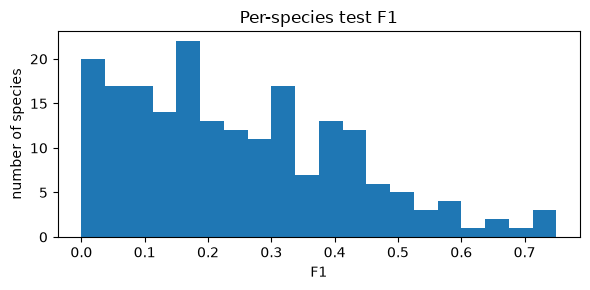

In [9]:
per_class = pd.Series(f1_score(y_test, y_pred, average=None, labels=model.classes_),
                      index=class_names.loc[model.classes_].values, name='F1')
print('Best classified species:');  print(per_class.nlargest(8).round(3).to_string())
print('\nWorst classified species:'); print(per_class.nsmallest(8).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(per_class, bins=20, color='tab:blue')
ax.set(title='Per-species test F1', xlabel='F1', ylabel='number of species')
plt.tight_layout()
plt.show()

## 8. Interpretation

The main advantage of a decision tree is that it is transparent. Below we show the top of the tree, its first rules as text, and the attributes it relies on most.

- Only the **top 3 levels** are drawn. The full tree has 46 levels and thousands of leaves, but the first splits are the most informative ones (they apply to the most images).
- **Caveat on feature importance:** the tree's built-in importance (mean decrease in impurity) is computed on training data and tends to favour features that are split on often. It shows what the tree *uses*, not necessarily what *generalises*. The Random Forest notebook adds permutation importance as a more reliable check.
- Importances are also **summed per attribute group** (e.g. all 15 `has_bill_color` columns). One-hot encoding spreads a body part's importance across many columns, so the group totals are easier to compare.

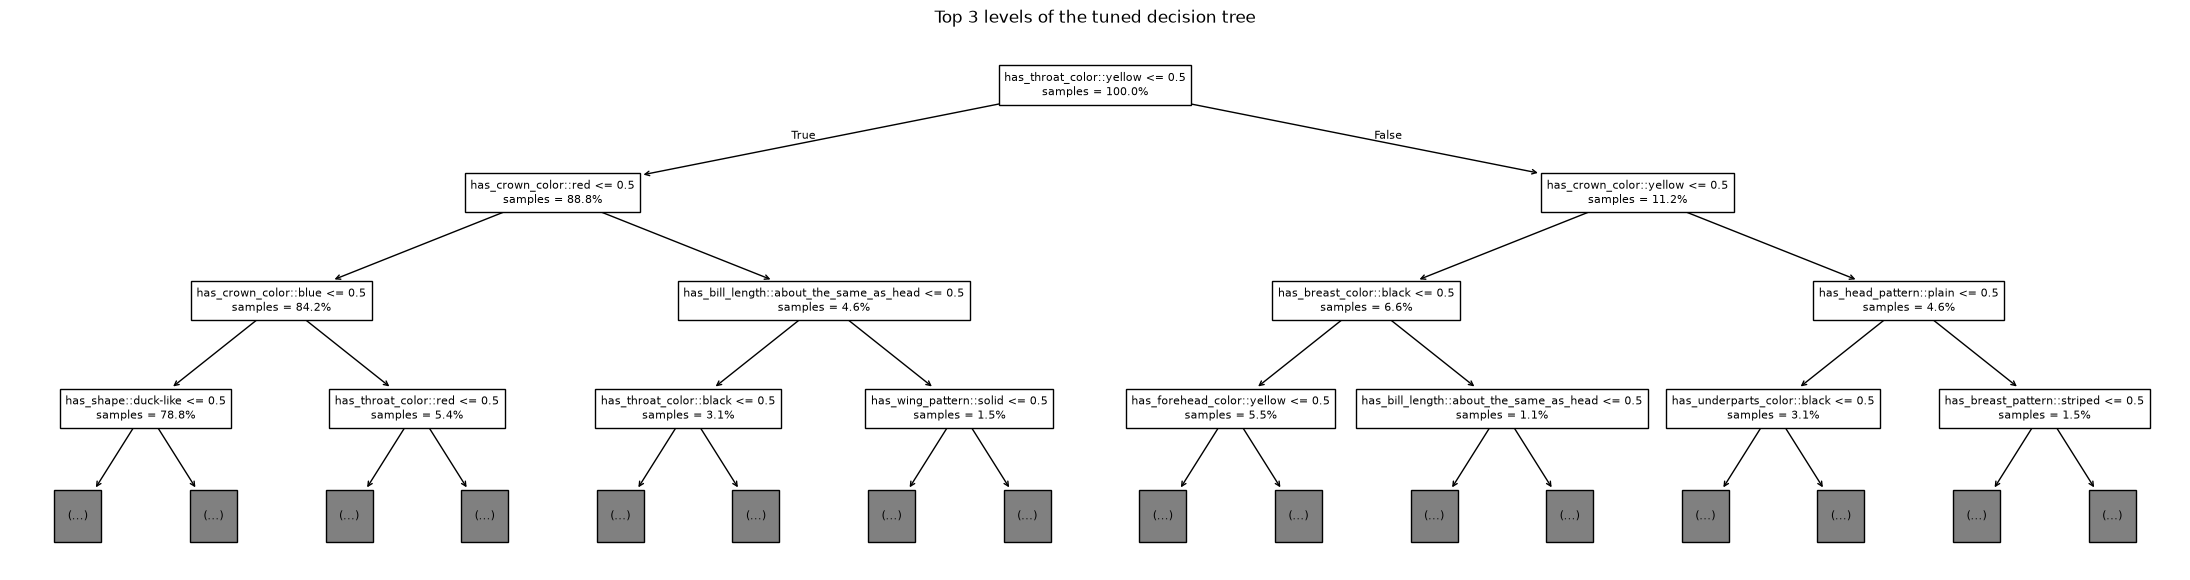

In [10]:
import re

fig, ax = plt.subplots(figsize=(28, 7))
nodes = plot_tree(model, max_depth=3, feature_names=list(X_train.columns),
                  impurity=False, proportion=True, fontsize=8, ax=ax)
# Each node would print a 200-class probability vector; keep only the split rule and sample share
for node in nodes:
    node.set_text(re.sub(r'\nvalue = \[.*?\]', '', node.get_text(), flags=re.S))
ax.set_title('Top 3 levels of the tuned decision tree')
plt.show()

In [11]:
print(export_text(model, feature_names=list(X_train.columns), max_depth=3, show_weights=False))

|--- has_throat_color::yellow <= 0.50
|   |--- has_crown_color::red <= 0.50
|   |   |--- has_crown_color::blue <= 0.50
|   |   |   |--- has_shape::duck-like <= 0.50
|   |   |   |   |--- truncated branch of depth 43
|   |   |   |--- has_shape::duck-like >  0.50
|   |   |   |   |--- truncated branch of depth 25
|   |   |--- has_crown_color::blue >  0.50
|   |   |   |--- has_throat_color::red <= 0.50
|   |   |   |   |--- truncated branch of depth 18
|   |   |   |--- has_throat_color::red >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- has_crown_color::red >  0.50
|   |   |--- has_bill_length::about_the_same_as_head <= 0.50
|   |   |   |--- has_throat_color::black <= 0.50
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- has_throat_color::black >  0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- has_bill_length::about_the_same_as_head >  0.50
|   |   |   |--- has_wing_pattern::solid <= 0.50
|   |   |   |   |--- truncated branch of depth 

features used by the tree: 276 / 312


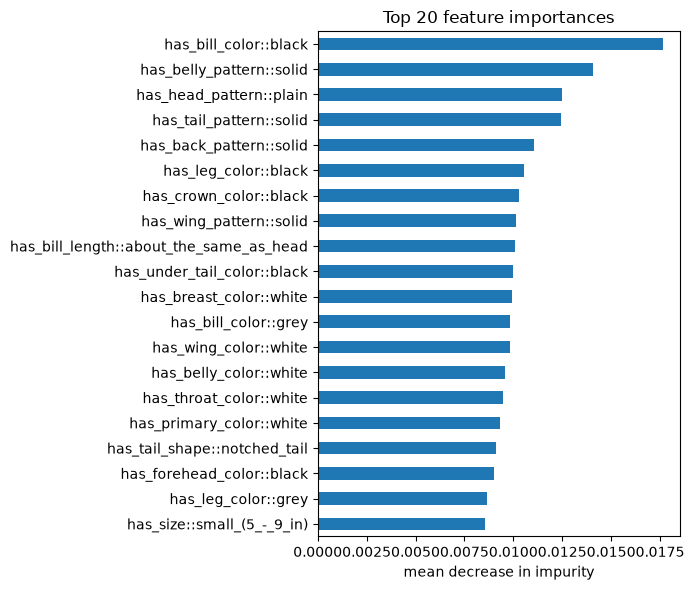

,importance (by attribute group)
has_bill_color,0.059
has_wing_color,0.050
has_head_pattern,0.049
has_primary_color,0.047
has_throat_color,0.045
has_crown_color,0.044
has_leg_color,0.044
has_forehead_color,0.043
has_upperparts_color,0.042
has_nape_color,0.041


In [12]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)
print(f'features used by the tree: {(importances > 0).sum()} / {len(importances)}')

fig, ax = plt.subplots(figsize=(7, 6))
importances.nlargest(20).sort_values().plot.barh(ax=ax, color='tab:blue')
ax.set(title='Top 20 feature importances', xlabel='mean decrease in impurity')
plt.tight_layout()
plt.show()

group_imp = importances.groupby(importances.index.str.split('::').str[0]).sum().sort_values(ascending=False)
group_imp.head(10).round(3).to_frame('importance (by attribute group)')

## 9. Summary

The cell below prints the headline numbers for the report.

**Findings (with `RANDOM_STATE = 42`):**
- The tree reaches about **24.7% test accuracy** (macro-F1 about 0.245). That is roughly 50× chance (0.5%), but low in absolute terms. The labels come from a single noisy annotator per image, with only about 30 training images per species.
- **Tuning did not beat the default tree.** The best grid configuration is effectively the unpruned tree (light pruning with `ccp_alpha = 1e-4` scores the same). Every form of regularisation lowers CV accuracy (§3 curves). With 200 classes and about 30 images each, leaves need to be tiny to separate species, so restricting depth or leaf size merges species together.
- The gap between about 100% train accuracy and about 25% CV accuracy shows **very high variance**. This is exactly the weakness a Random Forest addresses by averaging many decorrelated trees, which motivates the next notebook.
- **Feature variants:** A (0.247) ≥ C (0.243) ≥ B (0.243) in CV accuracy. The differences are within one standard deviation across folds (about 0.005–0.009), so explicitly encoding "not visible" gives no measurable benefit for a single tree. We keep A as the simplest option, and B/C should be re-tested with the Random Forest.
- **Errors are biologically sensible:** American vs Fish Crow, Northern vs Louisiana Waterthrush, Anna vs Ruby-throated Hummingbird, Blue Grosbeak vs Indigo Bunting. These species pairs look nearly identical in attribute terms. Brightly coloured, distinctive species (Cardinal, Pileated Woodpecker, Rose-breasted Grosbeak) are classified best.
- **Most useful attributes:** colour groups dominate (bill, wing, primary, throat, crown), along with head pattern. The root split is `has_throat_color::yellow`.

The Random Forest notebook should reuse the same CV setup and feature variant so the two models can be compared directly.

In [13]:
summary = pd.Series({'chance': 1 / y_train.nunique(), 'baseline test accuracy': baseline_test, **results})
summary

chance                       0.005
baseline test accuracy    0.246807
variant                          A
train_accuracy            0.999333
cv_accuracy               0.246581
test_accuracy             0.246807
test_f1_macro             0.245224
test_top5_accuracy        0.263548
depth                           46
leaves                        3429
dtype: object

## 10. Limitations

- **Single seed:** all results use `RANDOM_STATE = 42`. The fold-to-fold standard deviation (about 0.5 points) shows the CV noise, but variation across different seeds and fold assignments was not measured.
- **Label noise and identical vectors:** each image was annotated by one worker, and 16 groups of images have identical attributes but different species. Both put a ceiling on any tabular model.
- **Untested cleaning option:** the "drop guessing positives" switch in `dataPrep.ipynb` was not evaluated.
- **Training-data importances:** the feature importances in §8 come from the training data, so they describe the fitted tree rather than generalisation (see the caveat there).